Transfer learning using a pretrained ResNet-18 model on ImageNet:

I begin by importing the pretrained model and testing it on a randomly selected satleite image from each category.

Actual: AnnualCrop
Predicted: nail
Confidence: 3.32%
----------------------------------------
Actual: Forest
Predicted: dugong
Confidence: 10.50%
----------------------------------------
Actual: HerbaceousVegetation
Predicted: armadillo
Confidence: 3.37%
----------------------------------------
Actual: Highway
Predicted: sunglass
Confidence: 8.90%
----------------------------------------
Actual: Industrial
Predicted: waffle iron
Confidence: 16.40%
----------------------------------------
Actual: Pasture
Predicted: bulletproof vest
Confidence: 24.54%
----------------------------------------
Actual: PermanentCrop
Predicted: comic book
Confidence: 5.52%
----------------------------------------
Actual: Residential
Predicted: isopod
Confidence: 5.57%
----------------------------------------
Actual: River
Predicted: Petri dish
Confidence: 5.67%
----------------------------------------
Actual: SeaLake
Predicted: tiger shark
Confidence: 35.69%
----------------------------------------


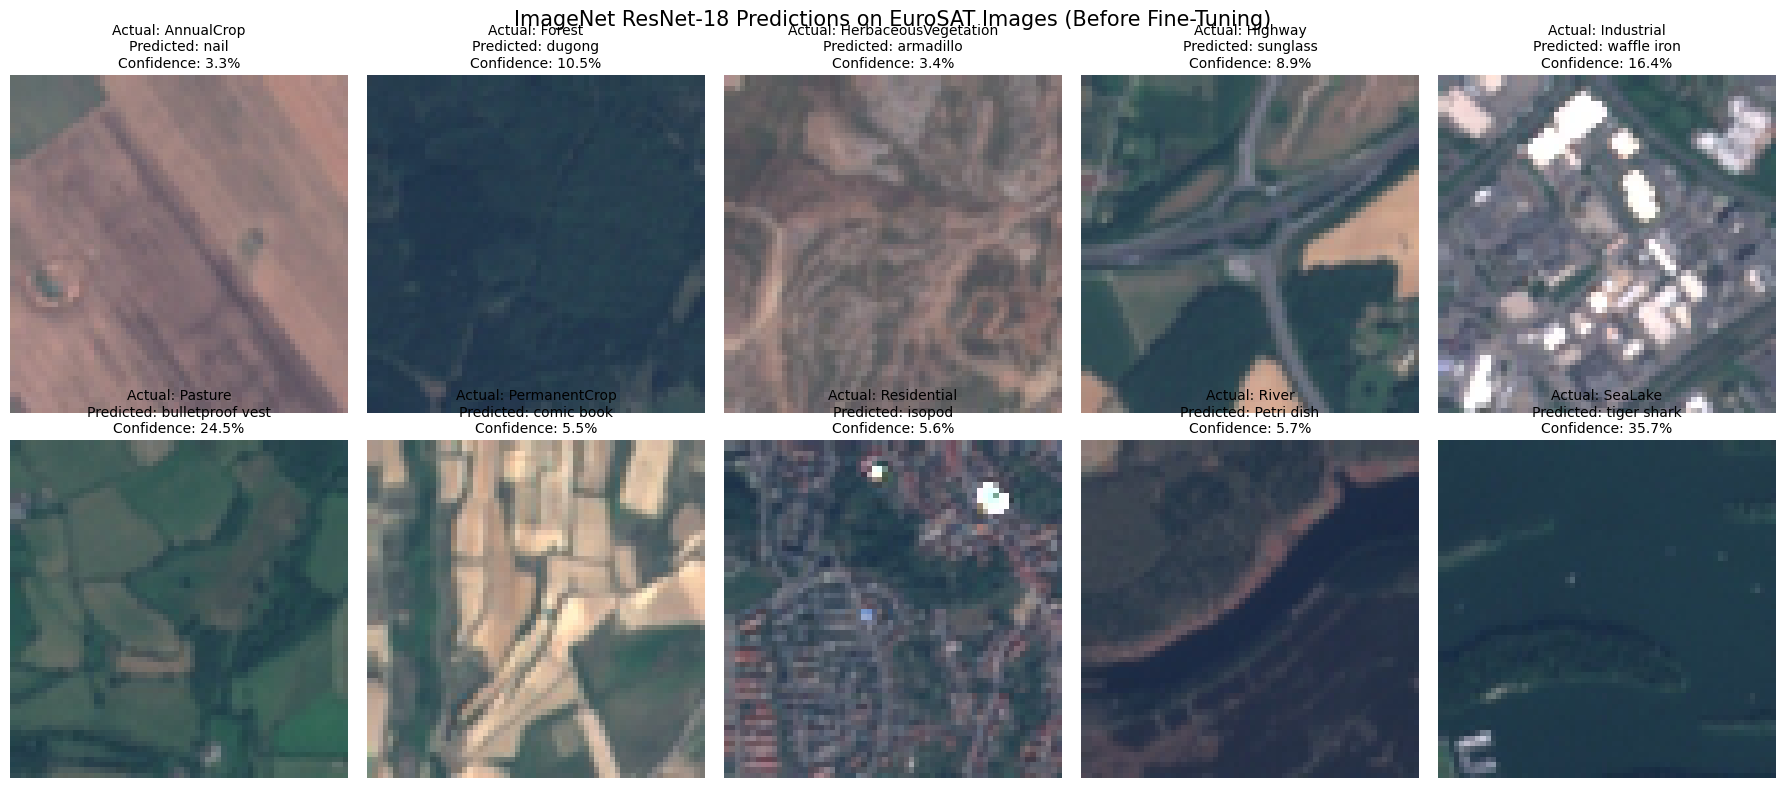

In [ ]:
import torch
import random
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from torchvision.models import resnet18, ResNet18_Weights

# For reproducible random selection
random.seed(42)

# Load original ImageNet-pretrained ResNet-18
weights1 = ResNet18_Weights.DEFAULT
model1 = resnet18(weights=weights)
model1.eval()

# ImageNet preprocessing
transform = weights1.transforms()

# Original ImageNet class names
imagenet_classes = weights1.meta["categories"]

# Path to EuroSAT training images
data_path = Path("../../data/train")

# Get the 10 EuroSAT categories
classes = sorted([
    folder.name
    for folder in data_path.iterdir()
    if folder.is_dir()
])

# Create a figure to display the images
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

with torch.inference_mode():

    for i, class_name in enumerate(classes):

        # Find all images belonging to this class
        image_paths = list(
            (data_path / class_name).glob("*.jpg")
        )

        # Randomly select one image
        image_path = random.choice(image_paths)

        # Open original image
        image = Image.open(image_path).convert("RGB")

        # Preprocess for ResNet-18
        input_tensor = transform(image).unsqueeze(0)

        # Generate prediction
        output = model1(input_tensor)

        # Convert output to probabilities
        probabilities = torch.softmax(output, dim=1)

        # Get highest probability prediction
        confidence, predicted_class = probabilities.max(dim=1)

        prediction = imagenet_classes[predicted_class.item()]
        confidence_pct = confidence.item() * 100

        # Display original satellite image
        axes[i].imshow(image)
        axes[i].axis("off")

        axes[i].set_title(
            f"Actual: {class_name}\n"
            f"Predicted: {prediction}\n"
            f"Confidence: {confidence_pct:.1f}%",
            fontsize=10
        )

        # Print results
        print(f"Actual: {class_name}")
        print(f"Predicted: {prediction}")
        print(f"Confidence: {confidence_pct:.2f}%")
        print("-" * 40)

plt.suptitle(
    "ImageNet ResNet-18 Predictions on EuroSAT Images (Before Fine-Tuning)",
    fontsize=15
)

plt.tight_layout()
plt.show()

As expected, confidence is fairly low for most of the classifications. However, it does predict the sealake image to be a tiger shark with 35.7% accuracy which is perhaps suprising.

In [6]:
model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

The model contains 6 key areas, we only wnat to adjust the final layer which seperates the images in to classes. Currently, it has 1000 differnet categories, as per the ImageNet data-set. We want to adjust the final layer so that it only has 10 categories and freeze the remaining layers. We can then train the final model on our satelite images.

In [7]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# Load original ImageNet-pretrained ResNet-18
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# Freeze all pretrained layers
for param in model.parameters():
    param.requires_grad = False

# Replace the final classification layer
# Original: 512 inputs -> 1000 ImageNet classes
# New:      512 inputs -> 10 EuroSAT classes
model.fc = nn.Linear(model.fc.in_features, 10)

# Define loss function
criterion = nn.CrossEntropyLoss()

# Optimiser only updates the final layer
optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

# Keep the pretrained backbone's BatchNorm statistics fixed
model.eval()

# Check the new final layer
print("New classification layer:", model.fc)

# Check number of trainable parameters
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

New classification layer: Linear(in_features=512, out_features=10, bias=True)
Trainable parameters: 5130


The 17th layer extracts 512 features so since we have 10 of our own categories, thats 512 X 10 paraemters to train in addition to one more individual bias parameter per category. so 5130 in total.

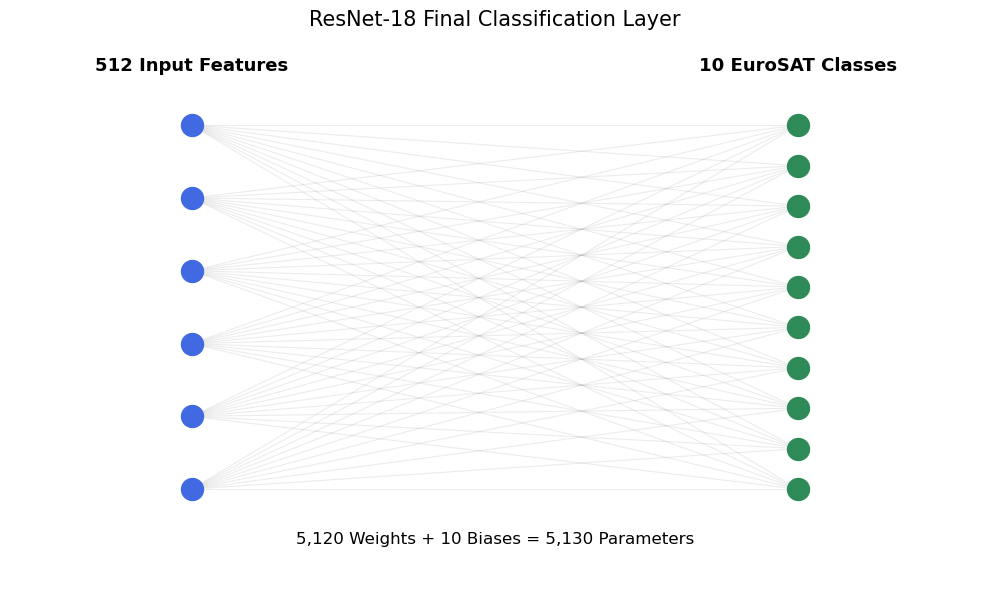

In [8]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(10, 6))

# Draw a simplified network
input_y = np.linspace(0, 1, 6)
output_y = np.linspace(0, 1, 10)

# Connections between neurons
for y1 in input_y:
    for y2 in output_y:
        ax.plot([0, 1], [y1, y2],
                color="gray", alpha=0.15, linewidth=0.8)

# Input feature neurons
ax.scatter(
    np.zeros(6), input_y,
    s=250, color="royalblue", zorder=3
)

# Output class neurons
ax.scatter(
    np.ones(10), output_y,
    s=250, color="seagreen", zorder=3
)

# Labels
ax.text(0, 1.15, "512 Input Features",
        ha="center", fontsize=13, fontweight="bold")

ax.text(1, 1.15, "10 EuroSAT Classes",
        ha="center", fontsize=13, fontweight="bold")

ax.text(0.5, -0.15,
        "5,120 Weights + 10 Biases = 5,130 Parameters",
        ha="center", fontsize=12)

ax.set_xlim(-0.3, 1.3)
ax.set_ylim(-0.25, 1.25)
ax.axis("off")

plt.title("ResNet-18 Final Classification Layer", fontsize=15)
plt.tight_layout()
plt.show()

Im going to test how long training takes on a small subset if the data-set 1000 total images and only 1 epoch.

In [11]:
from pathlib import Path
from torchvision import datasets
from torchvision.models import ResNet18_Weights

# Locate EuroSAT training images
data_path = Path("../../data/train")

# Use the pretrained ResNet-18 preprocessing
weights = ResNet18_Weights.DEFAULT
transform = weights.transforms()

# Load the EuroSAT dataset
dataset = datasets.ImageFolder(
    root=data_path,
    transform=transform
)

print("Total images:", len(dataset))
print("Classes:", dataset.classes)

Total images: 21600
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [14]:
import numpy as np
from torch.utils.data import Subset, DataLoader

# Set random seed for reproducibility
rng = np.random.default_rng(42)

# Select 100 images from each of the 10 classes
images_per_class = 100
subset_indices = []

for class_id in range(len(dataset.classes)):

    class_indices = np.where(
        np.array(dataset.targets) == class_id
    )[0]

    selected = rng.choice(
        class_indices,
        size=images_per_class,
        replace=False
    )

    subset_indices.extend(selected.tolist())

# Create small training dataset
small_train_dataset = Subset(dataset, subset_indices)

# Create DataLoader
small_train_loader = DataLoader(
    small_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

print("Training images:", len(small_train_dataset))
print("Batches:", len(small_train_loader))

Training images: 1000
Batches: 32


In [16]:
import torch

# Select the best available computing device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)

# Move model to the selected device
model = model.to(device)

Using device: mps


In [17]:
import time

# Keep frozen backbone in evaluation mode
model.eval()

start_time = time.perf_counter()

for images, labels in small_train_loader:

    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad(set_to_none=True)

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

# Synchronise GPU operations before measuring elapsed time
if device.type == "cuda":
    torch.cuda.synchronize()
elif device.type == "mps":
    torch.mps.synchronize()

elapsed = time.perf_counter() - start_time

print(f"Training time: {elapsed:.2f} seconds")
print(f"Time per image: {elapsed / 1000:.4f} seconds")

Training time: 15.12 seconds
Time per image: 0.0151 seconds


Using linear scaling, the estimated run time for training the full model, is 54 minutes.

In [18]:
from torch.utils.data import Subset, DataLoader
import numpy as np

# Identify images NOT used during training
all_indices = np.arange(len(dataset))

validation_indices = np.setdiff1d(
    all_indices,
    subset_indices
)

# Randomly choose 20 validation images per class
rng_val = np.random.default_rng(123)

selected_val_indices = []

for class_id in range(len(dataset.classes)):

    class_indices = [
        i for i in validation_indices
        if dataset.targets[i] == class_id
    ]

    selected = rng_val.choice(
        class_indices,
        size=20,
        replace=False
    )

    selected_val_indices.extend(selected.tolist())

# Create validation dataset
val_dataset = Subset(dataset, selected_val_indices)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Validation images:", len(val_dataset))

Validation images: 200


In [19]:
import torch
import time

def validate_model(model, val_loader, criterion, device):

    # Evaluation mode preserves pretrained BatchNorm statistics
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    start_time = time.perf_counter()

    # Disable gradient calculations
    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            # Generate predictions
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            # Get predicted class
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    # Synchronise GPU before stopping timer
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()

    elapsed = time.perf_counter() - start_time

    # Calculate average metrics
    avg_loss = total_loss / total
    accuracy = 100 * correct / total

    print(f"Validation accuracy: {accuracy:.2f}%")
    print(f"Validation loss: {avg_loss:.4f}")
    print(f"Validation time: {elapsed:.2f} seconds")

    return accuracy, avg_loss, elapsed

In [20]:
val_accuracy, val_loss, val_time = validate_model(
    model,
    val_loader,
    criterion,
    device
)

Validation accuracy: 75.50%
Validation loss: 1.2984
Validation time: 2.74 seconds


Testing on a small set of 200 images yeilds an accuracy of 75.5%

In [21]:
import torch
import torch.nn as nn
import time
import pandas as pd

from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader

def tune_resnet18(
    learning_rates,
    batch_sizes,
    epochs=2
):

    results = []
    best_accuracy = -1
    best_model = None
    best_config = None

    total_experiments = len(learning_rates) * len(batch_sizes)
    experiment = 0

    for lr in learning_rates:
        for batch_size in batch_sizes:

            experiment += 1

            print(f"\nExperiment {experiment}/{total_experiments}")
            print(f"Learning rate: {lr}")
            print(f"Batch size: {batch_size}")

            # Reproducible initialization
            torch.manual_seed(42)

            # Fresh pretrained ResNet-18
            model_trial = resnet18(
                weights=ResNet18_Weights.DEFAULT
            )

            # Freeze pretrained layers
            for param in model_trial.parameters():
                param.requires_grad = False

            # New 10-class classification layer
            model_trial.fc = nn.Linear(
                model_trial.fc.in_features,
                10
            )

            model_trial = model_trial.to(device)

            # Keep frozen BatchNorm statistics fixed
            model_trial.eval()

            criterion = nn.CrossEntropyLoss()

            optimizer = torch.optim.Adam(
                model_trial.fc.parameters(),
                lr=lr
            )

            train_loader = DataLoader(
                small_train_dataset,
                batch_size=batch_size,
                shuffle=True,
                num_workers=0,
                generator=torch.Generator().manual_seed(42)
            )

            start_time = time.perf_counter()

            # TRAINING
            for epoch in range(epochs):

                model_trial.eval()

                running_loss = 0
                correct = 0
                total = 0

                for images, labels in train_loader:

                    images = images.to(device)
                    labels = labels.to(device)

                    optimizer.zero_grad(set_to_none=True)

                    outputs = model_trial(images)
                    loss = criterion(outputs, labels)

                    loss.backward()
                    optimizer.step()

                    running_loss += loss.item() * labels.size(0)

                    predictions = outputs.argmax(dim=1)
                    correct += (predictions == labels).sum().item()
                    total += labels.size(0)

                train_accuracy = 100 * correct / total

                print(
                    f"Epoch {epoch+1}/{epochs}: "
                    f"Training accuracy = {train_accuracy:.2f}%"
                )

            # Ensure GPU has completed its operations
            if device.type == "mps":
                torch.mps.synchronize()
            elif device.type == "cuda":
                torch.cuda.synchronize()

            training_time = time.perf_counter() - start_time

            # VALIDATION
            model_trial.eval()

            val_correct = 0
            val_total = 0
            val_loss = 0

            with torch.inference_mode():

                for images, labels in val_loader:

                    images = images.to(device)
                    labels = labels.to(device)

                    outputs = model_trial(images)
                    loss = criterion(outputs, labels)

                    val_loss += loss.item() * labels.size(0)

                    predictions = outputs.argmax(dim=1)

                    val_correct += (
                        predictions == labels
                    ).sum().item()

                    val_total += labels.size(0)

            val_accuracy = 100 * val_correct / val_total
            val_loss = val_loss / val_total

            print(f"Validation accuracy: {val_accuracy:.2f}%")
            print(f"Training time: {training_time:.2f} seconds")

            # Store experiment results
            results.append({
                "Learning Rate": lr,
                "Batch Size": batch_size,
                "Epochs": epochs,
                "Train Accuracy (%)": train_accuracy,
                "Val Accuracy (%)": val_accuracy,
                "Val Loss": val_loss,
                "Training Time (s)": training_time
            })

            # Save the best model
            if val_accuracy > best_accuracy:

                best_accuracy = val_accuracy
                best_model = model_trial

                best_config = {
                    "learning_rate": lr,
                    "batch_size": batch_size,
                    "epochs": epochs
                }

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        by="Val Accuracy (%)",
        ascending=False
    ).reset_index(drop=True)

    return results_df, best_model, best_config

In [22]:
learning_rates = [0.0001, 0.001, 0.01]
batch_sizes = [32, 64]

results_df, best_model, best_config = tune_resnet18(
    learning_rates=learning_rates,
    batch_sizes=batch_sizes,
    epochs=2
)

display(results_df)

print("\nBest hyperparameters:")
print(best_config)


Experiment 1/6
Learning rate: 0.0001
Batch size: 32
Epoch 1/2: Training accuracy = 22.30%
Epoch 2/2: Training accuracy = 34.20%
Validation accuracy: 36.50%
Training time: 19.55 seconds

Experiment 2/6
Learning rate: 0.0001
Batch size: 64
Epoch 1/2: Training accuracy = 19.10%
Epoch 2/2: Training accuracy = 27.70%
Validation accuracy: 31.00%
Training time: 22.64 seconds

Experiment 3/6
Learning rate: 0.001
Batch size: 32
Epoch 1/2: Training accuracy = 48.70%
Epoch 2/2: Training accuracy = 83.50%
Validation accuracy: 83.00%
Training time: 22.26 seconds

Experiment 4/6
Learning rate: 0.001
Batch size: 64
Epoch 1/2: Training accuracy = 34.40%
Epoch 2/2: Training accuracy = 78.00%
Validation accuracy: 78.50%
Training time: 32.62 seconds

Experiment 5/6
Learning rate: 0.01
Batch size: 32
Epoch 1/2: Training accuracy = 71.40%
Epoch 2/2: Training accuracy = 92.30%
Validation accuracy: 87.50%
Training time: 17.99 seconds

Experiment 6/6
Learning rate: 0.01
Batch size: 64
Epoch 1/2: Training acc

,Learning Rate,Batch Size,Epochs,Train Accuracy (%),Val Accuracy (%),Val Loss,Training Time (s)
0,0.0100,32,2,92.3,87.5,0.387575,17.985991
1,0.0100,64,2,88.3,87.5,0.405938,21.214372
2,0.0010,32,2,83.5,83.0,0.827393,22.255999
3,0.0010,64,2,78.0,78.5,1.127678,32.624881
4,0.0001,32,2,34.2,36.5,2.007089,19.552739
5,0.0001,64,2,27.7,31.0,2.124056,22.636014



Best hyperparameters:
{'learning_rate': 0.01, 'batch_size': 32, 'epochs': 2}


More epochs is clearly better as well as a higher learning rate. The batch size of 32 performed the same as 64 with a fats run time. This may be important for scalability.

In [23]:
learning_rates = [0.003, 0.01, 0.02, 0.03, 0.05]
batch_sizes = [32]

results_lr, best_model_lr, best_config_lr = tune_resnet18(
    learning_rates=learning_rates,
    batch_sizes=batch_sizes,
    epochs=2
)

display(results_lr)
print("Best configuration:", best_config_lr)


Experiment 1/5
Learning rate: 0.003
Batch size: 32
Epoch 1/2: Training accuracy = 66.70%
Epoch 2/2: Training accuracy = 89.30%
Validation accuracy: 84.50%
Training time: 24.08 seconds

Experiment 2/5
Learning rate: 0.01
Batch size: 32
Epoch 1/2: Training accuracy = 71.40%
Epoch 2/2: Training accuracy = 92.30%
Validation accuracy: 87.50%
Training time: 22.86 seconds

Experiment 3/5
Learning rate: 0.02
Batch size: 32
Epoch 1/2: Training accuracy = 72.50%
Epoch 2/2: Training accuracy = 91.80%
Validation accuracy: 83.00%
Training time: 23.69 seconds

Experiment 4/5
Learning rate: 0.03
Batch size: 32
Epoch 1/2: Training accuracy = 66.10%
Epoch 2/2: Training accuracy = 90.50%
Validation accuracy: 88.50%
Training time: 18.26 seconds

Experiment 5/5
Learning rate: 0.05
Batch size: 32
Epoch 1/2: Training accuracy = 63.40%
Epoch 2/2: Training accuracy = 89.10%
Validation accuracy: 85.50%
Training time: 21.49 seconds


,Learning Rate,Batch Size,Epochs,Train Accuracy (%),Val Accuracy (%),Val Loss,Training Time (s)
0,0.030,32,2,90.5,88.5,0.495073,18.261671
1,0.010,32,2,92.3,87.5,0.387575,22.863215
2,0.050,32,2,89.1,85.5,0.797677,21.490437
3,0.003,32,2,89.3,84.5,0.490403,24.075988
4,0.020,32,2,91.8,83.0,0.489142,23.690380


Best configuration: {'learning_rate': 0.03, 'batch_size': 32, 'epochs': 2}


Learning rate of 0.03 performs the best on validation but it has a higher cross entropy loss than 0.01 . This indicates iut makes more comnfident inccorect guesses. Its worth exploring 0.01 - 0.03 further with more epochs and more validation data.

In [25]:
import numpy as np
from torch.utils.data import Subset, DataLoader

rng_val = np.random.default_rng(123)

# Exclude the 1000 training images
available_indices = np.setdiff1d(
    np.arange(len(dataset)),
    subset_indices
)

val_indices = []

# Select 100 images from each EuroSAT class
for class_id in range(len(dataset.classes)):

    class_indices = [
        i for i in available_indices
        if dataset.targets[i] == class_id
    ]

    selected = rng_val.choice(
        class_indices,
        size=100,
        replace=False
    )

    val_indices.extend(selected.tolist())

val_dataset = Subset(dataset, val_indices)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

assert set(subset_indices).isdisjoint(val_indices)

print("Training images:", len(small_train_dataset))
print("Validation images:", len(val_dataset))

Training images: 1000
Validation images: 1000


In [26]:
import torch
import torch.nn as nn
import pandas as pd
import time
import copy

from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader

learning_rates = [0.01, 0.02, 0.03]
epochs = 5
batch_size = 32

results = []
best_models = {}

# Use your existing 1000-image training subset
train_loader = DataLoader(
    small_train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

for lr in learning_rates:

    print(f"\n{'=' * 55}")
    print(f"Learning rate: {lr}")
    print(f"{'=' * 55}")

    # Same initial weights across experiments
    torch.manual_seed(42)

    model_trial = resnet18(
        weights=ResNet18_Weights.DEFAULT
    )

    # Freeze pretrained backbone
    for param in model_trial.parameters():
        param.requires_grad = False

    # Replace final classifier
    model_trial.fc = nn.Linear(
        model_trial.fc.in_features,
        10
    )

    model_trial = model_trial.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model_trial.fc.parameters(),
        lr=lr
    )

    best_val_accuracy = -1
    best_state = None

    # Reset shuffle order for each experiment
    train_loader = DataLoader(
        small_train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(42)
    )

    for epoch in range(epochs):

        start_time = time.perf_counter()

        # TRAINING
        # Keep frozen BatchNorm layers in evaluation mode
        model_trial.eval()

        train_loss_sum = 0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            outputs = model_trial(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)
            train_correct += (
                predictions == labels
            ).sum().item()

            train_total += labels.size(0)

        train_loss = train_loss_sum / train_total
        train_accuracy = 100 * train_correct / train_total

        # VALIDATION
        model_trial.eval()

        val_loss_sum = 0
        val_correct = 0
        val_total = 0

        with torch.inference_mode():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model_trial(images)
                loss = criterion(outputs, labels)

                val_loss_sum += loss.item() * labels.size(0)

                predictions = outputs.argmax(dim=1)

                val_correct += (
                    predictions == labels
                ).sum().item()

                val_total += labels.size(0)

        val_loss = val_loss_sum / val_total
        val_accuracy = 100 * val_correct / val_total

        # Synchronise GPU for accurate timing
        if device.type == "mps":
            torch.mps.synchronize()
        elif device.type == "cuda":
            torch.cuda.synchronize()

        epoch_time = time.perf_counter() - start_time

        # Save best model for this learning rate
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_state = copy.deepcopy(model_trial.state_dict())

        results.append({
            "Learning Rate": lr,
            "Epoch": epoch + 1,
            "Train Accuracy": train_accuracy,
            "Val Accuracy": val_accuracy,
            "Train Loss": train_loss,
            "Val Loss": val_loss,
            "Epoch Time (s)": epoch_time
        })

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Acc: {val_accuracy:.2f}% | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Time: {epoch_time:.2f}s"
        )

    best_models[lr] = best_state

# Convert results to DataFrame
results_df = pd.DataFrame(results)

display(results_df)


Learning rate: 0.01
Epoch 1/5 | Train Acc: 71.40% | Val Acc: 87.70% | Train Loss: 0.8862 | Val Loss: 0.3876 | Time: 23.44s
Epoch 2/5 | Train Acc: 92.30% | Val Acc: 87.80% | Train Loss: 0.2685 | Val Loss: 0.3335 | Time: 22.73s
Epoch 3/5 | Train Acc: 94.50% | Val Acc: 87.30% | Train Loss: 0.1961 | Val Loss: 0.3614 | Time: 21.38s
Epoch 4/5 | Train Acc: 96.30% | Val Acc: 90.70% | Train Loss: 0.1430 | Val Loss: 0.2985 | Time: 23.15s
Epoch 5/5 | Train Acc: 98.20% | Val Acc: 89.60% | Train Loss: 0.1042 | Val Loss: 0.3175 | Time: 17.36s

Learning rate: 0.02
Epoch 1/5 | Train Acc: 72.50% | Val Acc: 86.60% | Train Loss: 0.9539 | Val Loss: 0.4411 | Time: 16.84s
Epoch 2/5 | Train Acc: 91.80% | Val Acc: 87.40% | Train Loss: 0.2500 | Val Loss: 0.4006 | Time: 18.82s
Epoch 3/5 | Train Acc: 93.50% | Val Acc: 88.20% | Train Loss: 0.1941 | Val Loss: 0.3643 | Time: 20.01s
Epoch 4/5 | Train Acc: 92.90% | Val Acc: 89.90% | Train Loss: 0.1976 | Val Loss: 0.3774 | Time: 19.09s
Epoch 5/5 | Train Acc: 97.70% |

,Learning Rate,Epoch,Train Accuracy,Val Accuracy,Train Loss,Val Loss,Epoch Time (s)
0,0.01,1,71.4,87.7,0.886154,0.387573,23.444124
1,0.01,2,92.3,87.8,0.268534,0.333537,22.725363
2,0.01,3,94.5,87.3,0.196055,0.361440,21.382763
3,0.01,4,96.3,90.7,0.142955,0.298513,23.148963
4,0.01,5,98.2,89.6,0.104210,0.317500,17.361398
5,0.02,1,72.5,86.6,0.953927,0.441111,16.840554
6,0.02,2,91.8,87.4,0.249996,0.400554,18.819790
7,0.02,3,93.5,88.2,0.194069,0.364331,20.008291
8,0.02,4,92.9,89.9,0.197593,0.377428,19.087501
9,0.02,5,97.7,87.6,0.085545,0.441909,15.874472


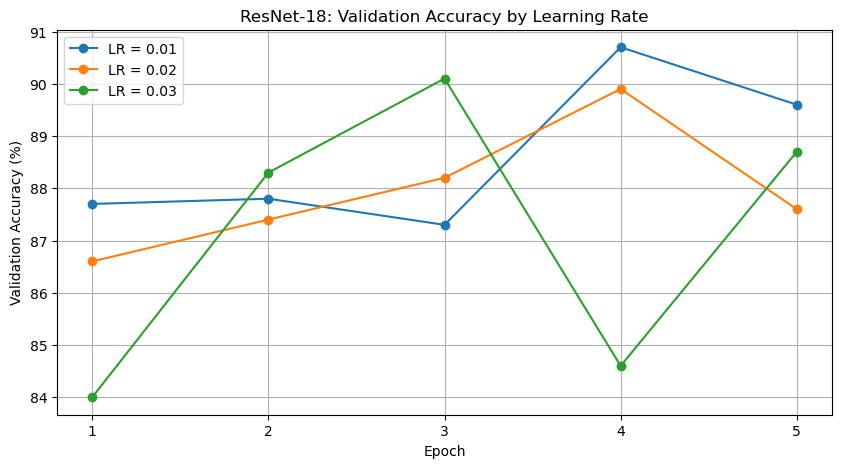

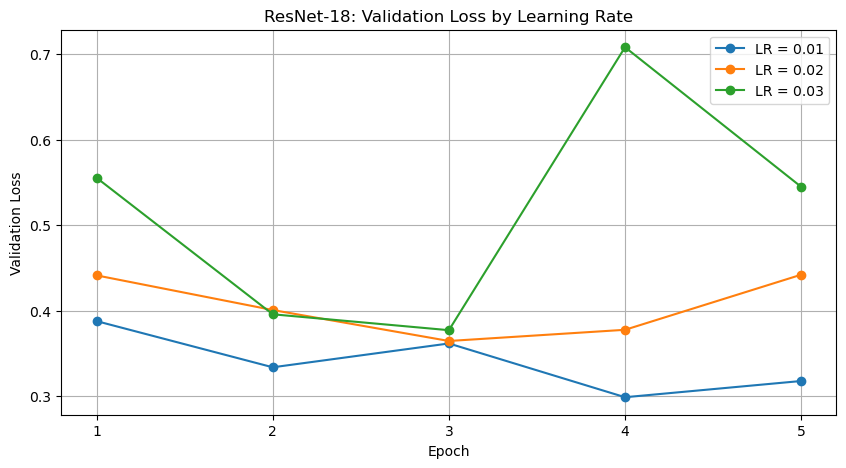

In [28]:
import matplotlib.pyplot as plt

# Validation accuracy
plt.figure(figsize=(10, 5))

for lr in learning_rates:
    subset = results_df[
        results_df["Learning Rate"] == lr
    ]

    plt.plot(
        subset["Epoch"],
        subset["Val Accuracy"],
        marker="o",
        label=f"LR = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("ResNet-18: Validation Accuracy by Learning Rate")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)
plt.show()


# Validation loss
plt.figure(figsize=(10, 5))

for lr in learning_rates:
    subset = results_df[
        results_df["Learning Rate"] == lr
    ]

    plt.plot(
        subset["Epoch"],
        subset["Val Loss"],
        marker="o",
        label=f"LR = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("ResNet-18: Validation Loss by Learning Rate")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)
plt.show()

The learning rate of 0.01 achieves both the highest validation accuracy as well as the lowest validation loss. Validation accuracy does appear to decrease at the last epoch whcih may be a sign of overfitting.

## Training and testing function for all training data using a learning rate if 0,01, a batch size of 32 and 5 epochs[¶](#Training-and-testing-function-for-all-training-data-using-a-learning-rate-if-0,01,-a-batch-size-of-32-and-5-epochs)

In [32]:
import torch
import torch.nn as nn
import time
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision import datasets
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader

# Reproducibility
torch.manual_seed(42)

# Dataset location
# Notebook located in individual-workflows/Oliwer
data_path = Path("../../data")

# ImageNet preprocessing
weights = ResNet18_Weights.DEFAULT
transform = weights.transforms()

# Load ALL training and testing images
train_dataset = datasets.ImageFolder(
    root=data_path / "train",
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root=data_path / "test",
    transform=transform
)

# Ensure class ordering is identical
assert train_dataset.classes == test_dataset.classes

# Hyperparameters
learning_rate = 0.01
batch_size = 32
epochs = 5

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

# Select device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# Load a fresh pretrained ResNet-18
model = resnet18(weights=weights)

# Freeze all pretrained layers
for param in model.parameters():
    param.requires_grad = False

# Replace final layer with 10 EuroSAT classes
model.fc = nn.Linear(model.fc.in_features, 10)

model = model.to(device)

# Loss function
criterion = nn.CrossEntropyLoss()

# Train only the final layer
optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=learning_rate
)

print("Device:", device)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Final classification layer:", model.fc)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
))

Device: mps
Training images: 21600
Testing images: 5400
Final classification layer: Linear(in_features=512, out_features=10, bias=True)
Trainable parameters: 5130


In [33]:
def train_model(model, train_loader, criterion, optimizer, device, epochs=5):

    # Preserve pretrained BatchNorm statistics
    model.eval()

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "epoch_time": []
    }

    start_time = time.perf_counter()

    for epoch in range(epochs):

        epoch_start = time.perf_counter()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            # Reset gradients
            optimizer.zero_grad(set_to_none=True)

            # Forward pass
            outputs = model(images)

            # Calculate classification loss
            loss = criterion(outputs, labels)

            # Backpropagation
            loss.backward()

            # Update final classification layer
            optimizer.step()

            # Accumulate training statistics
            running_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        # Synchronise GPU for accurate timing
        if device.type == "mps":
            torch.mps.synchronize()
        elif device.type == "cuda":
            torch.cuda.synchronize()

        epoch_time = time.perf_counter() - epoch_start

        train_loss = running_loss / total
        train_accuracy = 100 * correct / total

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["epoch_time"].append(epoch_time)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss: {train_loss:.4f} | "
            f"Training accuracy: {train_accuracy:.2f}% | "
            f"Time: {epoch_time/60:.2f} minutes",
            flush=True
        )

        print("-" * 60, flush=True)

    total_time = time.perf_counter() - start_time

    print("\nTraining completed!")
    print(f"Total training time: {total_time/60:.2f} minutes")

    return history, total_time

In [34]:
def validate_model(model, test_loader, criterion, device):

    # Evaluation mode
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    start_time = time.perf_counter()

    # Disable gradient calculations
    with torch.inference_mode():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            # Predictions
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    # Synchronise GPU
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

    evaluation_time = time.perf_counter() - start_time

    test_loss = total_loss / total
    test_accuracy = 100 * correct / total

    print("\nTEST RESULTS")
    print("=" * 40)
    print(f"Test images: {total}")
    print(f"Test accuracy: {test_accuracy:.2f}%")
    print(f"Test loss: {test_loss:.4f}")
    print(f"Evaluation time: {evaluation_time:.2f} seconds")

    return test_loss, test_accuracy, evaluation_time

In [35]:
# Train on all 21,600 training images
history, training_time = train_model(
    model,
    train_loader,
    criterion,
    optimizer,
    device,
    epochs=5
)

# Test on all 5,400 test images
test_loss, test_accuracy, test_time = validate_model(
    model,
    test_loader,
    criterion,
    device
)

Epoch 1/5 | Loss: 0.3098 | Training accuracy: 89.81% | Time: 4.60 minutes
------------------------------------------------------------
------------------------------------------------------------
Epoch 2/5 | Loss: 0.2210 | Training accuracy: 92.91% | Time: 3.77 minutes
------------------------------------------------------------
Epoch 3/5 | Loss: 0.2061 | Training accuracy: 93.64% | Time: 4.06 minutes
------------------------------------------------------------
Epoch 4/5 | Loss: 0.1972 | Training accuracy: 94.05% | Time: 3.01 minutes
------------------------------------------------------------
Epoch 5/5 | Loss: 0.1828 | Training accuracy: 94.53% | Time: 3.64 minutes
------------------------------------------------------------

Training completed!
Total training time: 19.09 minutes

TEST RESULTS
Test images: 5400
Test accuracy: 91.04%
Test loss: 0.3610
Evaluation time: 62.45 seconds


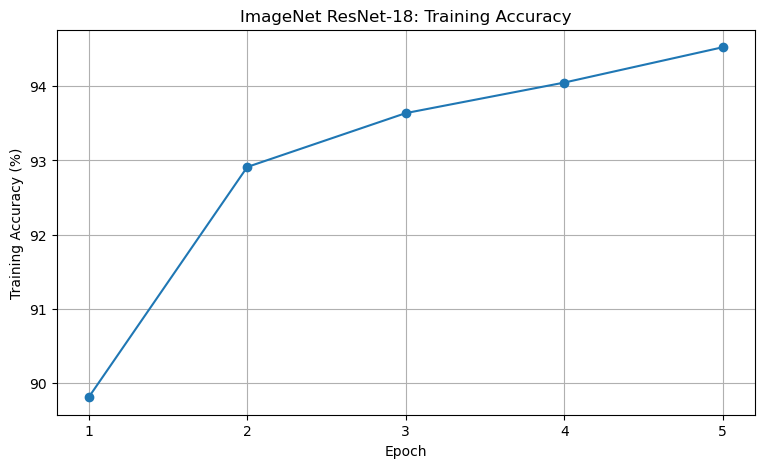

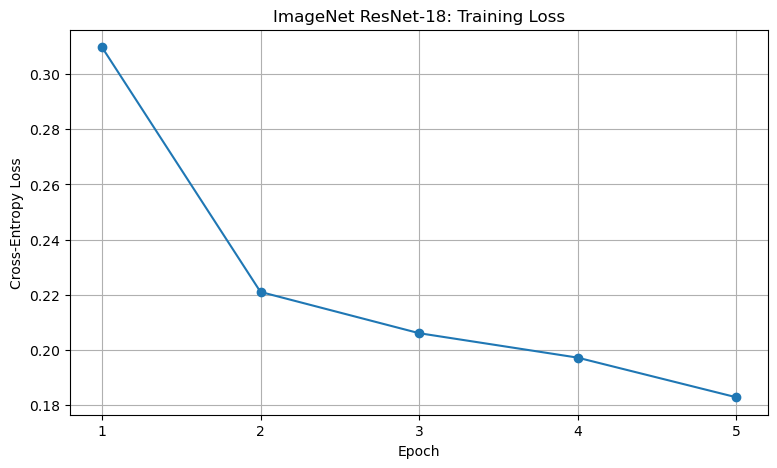

Model saved successfully!


In [42]:
# Plot training accuracy
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    history["train_accuracy"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.title("ImageNet ResNet-18: Training Accuracy")
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.show()

# Plot training loss
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    history["train_loss"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("ImageNet ResNet-18: Training Loss")
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.show()

# Save trained model
torch.save(
    model.state_dict(),
    "resnet18_imagenet_5epochs.pth"
)

print("Model saved successfully!")

This yeilds a high accuracy, but what if we train the model for another 5 epochs.

In [37]:
# Continue training the existing model for 5 more epochs
history_extra, extra_training_time = train_model(
    model,
    train_loader,
    criterion,
    optimizer,
    device,
    epochs=5
)

print("Model has now completed 10 epochs in total!")

Epoch 1/5 | Loss: 0.1920 | Training accuracy: 94.49% | Time: 5.52 minutes
------------------------------------------------------------
------------------------------------------------------------
Epoch 2/5 | Loss: 0.1711 | Training accuracy: 94.82% | Time: 5.51 minutes
------------------------------------------------------------
Epoch 3/5 | Loss: 0.1697 | Training accuracy: 95.03% | Time: 4.00 minutes
------------------------------------------------------------
Epoch 4/5 | Loss: 0.1608 | Training accuracy: 95.38% | Time: 3.54 minutes
------------------------------------------------------------
Epoch 5/5 | Loss: 0.1657 | Training accuracy: 95.22% | Time: 4.23 minutes
------------------------------------------------------------

Training completed!
Total training time: 22.81 minutes
Model has now completed 10 epochs in total!


In [44]:
import torch

history_5epochs = torch.load(
    "history_5epochs",
    map_location="cpu",
    weights_only=True
)

print(type(history_5epochs))
print(history_5epochs.keys())

<class 'collections.OrderedDict'>
odict_keys(['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean', 'layer1.0.bn1.running_var', 'layer1.0.bn1.num_batches_tracked', 'layer1.0.conv2.weight', 'layer1.0.bn2.weight', 'layer1.0.bn2.bias', 'layer1.0.bn2.running_mean', 'layer1.0.bn2.running_var', 'layer1.0.bn2.num_batches_tracked', 'layer1.1.conv1.weight', 'layer1.1.bn1.weight', 'layer1.1.bn1.bias', 'layer1.1.bn1.running_mean', 'layer1.1.bn1.running_var', 'layer1.1.bn1.num_batches_tracked', 'layer1.1.conv2.weight', 'layer1.1.bn2.weight', 'layer1.1.bn2.bias', 'layer1.1.bn2.running_mean', 'layer1.1.bn2.running_var', 'layer1.1.bn2.num_batches_tracked', 'layer2.0.conv1.weight', 'layer2.0.bn1.weight', 'layer2.0.bn1.bias', 'layer2.0.bn1.running_mean', 'layer2.0.bn1.running_var', 'layer2.0.bn1.num_batches_tracked', 'layer2.0.conv2.weight', 'layer2.0.b

In [46]:
print(history.keys())
print("Recorded epochs:", len(history["train_accuracy"]))

dict_keys(['train_loss', 'train_accuracy', 'epoch_time'])
Recorded epochs: 5


In [47]:
# Recover original five-epoch training history
history_5epochs = history.copy()

# Combine epochs 1-5 and epochs 6-10
history_10epochs = {
    "train_loss": (
        history_5epochs["train_loss"]
        + history_extra["train_loss"]
    ),
    "train_accuracy": (
        history_5epochs["train_accuracy"]
        + history_extra["train_accuracy"]
    ),
    "epoch_time": (
        history_5epochs["epoch_time"]
        + history_extra["epoch_time"]
    )
}

print("Total epochs:", len(history_10epochs["train_accuracy"]))

Total epochs: 10


In [48]:
test_loss_10, test_accuracy_10, test_time_10 = validate_model(
    model,
    test_loader,
    criterion,
    device
)

torch.save({
    "epoch": 10,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "history": history_10epochs
}, "resnet18_imagenet_10epochs_checkpoint.pth")

print("10-epoch model saved!")


TEST RESULTS
Test images: 5400
Test accuracy: 93.31%
Test loss: 0.3193
Evaluation time: 71.64 seconds
10-epoch model saved!


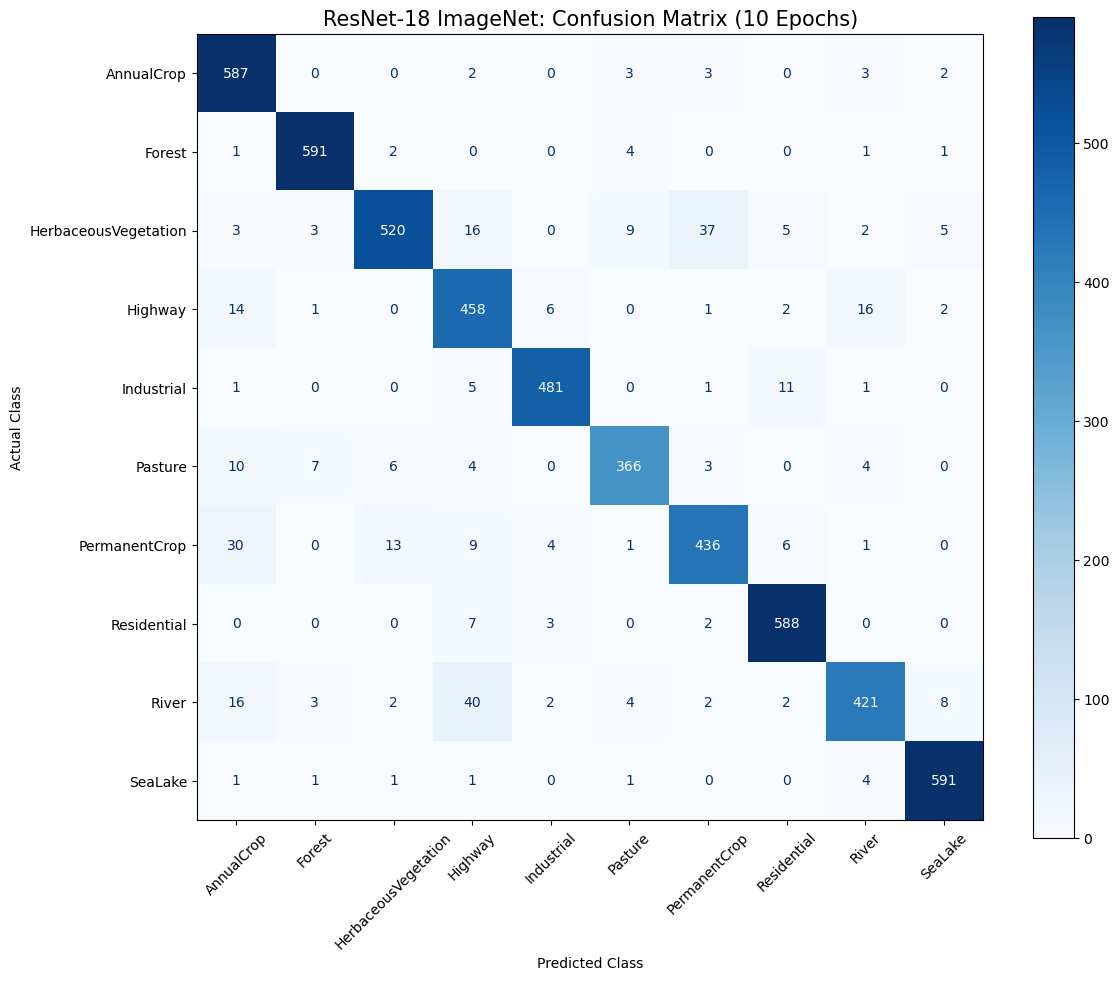

Test accuracy: 93.31%

Classification Report:
                      precision    recall  f1-score   support

          AnnualCrop       0.89      0.98      0.93       600
              Forest       0.98      0.98      0.98       600
HerbaceousVegetation       0.96      0.87      0.91       600
             Highway       0.85      0.92      0.88       500
          Industrial       0.97      0.96      0.97       500
             Pasture       0.94      0.92      0.93       400
       PermanentCrop       0.90      0.87      0.89       500
         Residential       0.96      0.98      0.97       600
               River       0.93      0.84      0.88       500
             SeaLake       0.97      0.98      0.98       600

            accuracy                           0.93      5400
           macro avg       0.93      0.93      0.93      5400
        weighted avg       0.93      0.93      0.93      5400



In [49]:
import torch
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Use your existing 10-epoch model
model.eval()

all_predictions = []
all_labels = []

# Predict all test images
with torch.inference_mode():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

# Calculate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions
)

# Display confusion matrix
fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=True
)

plt.title(
    "ResNet-18 ImageNet: Confusion Matrix (10 Epochs)",
    fontsize=15
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

# Print overall accuracy
accuracy = 100 * np.trace(cm) / np.sum(cm)

print(f"Test accuracy: {accuracy:.2f}%")

# Detailed classification report
print("\nClassification Report:")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=test_dataset.classes
    )
)

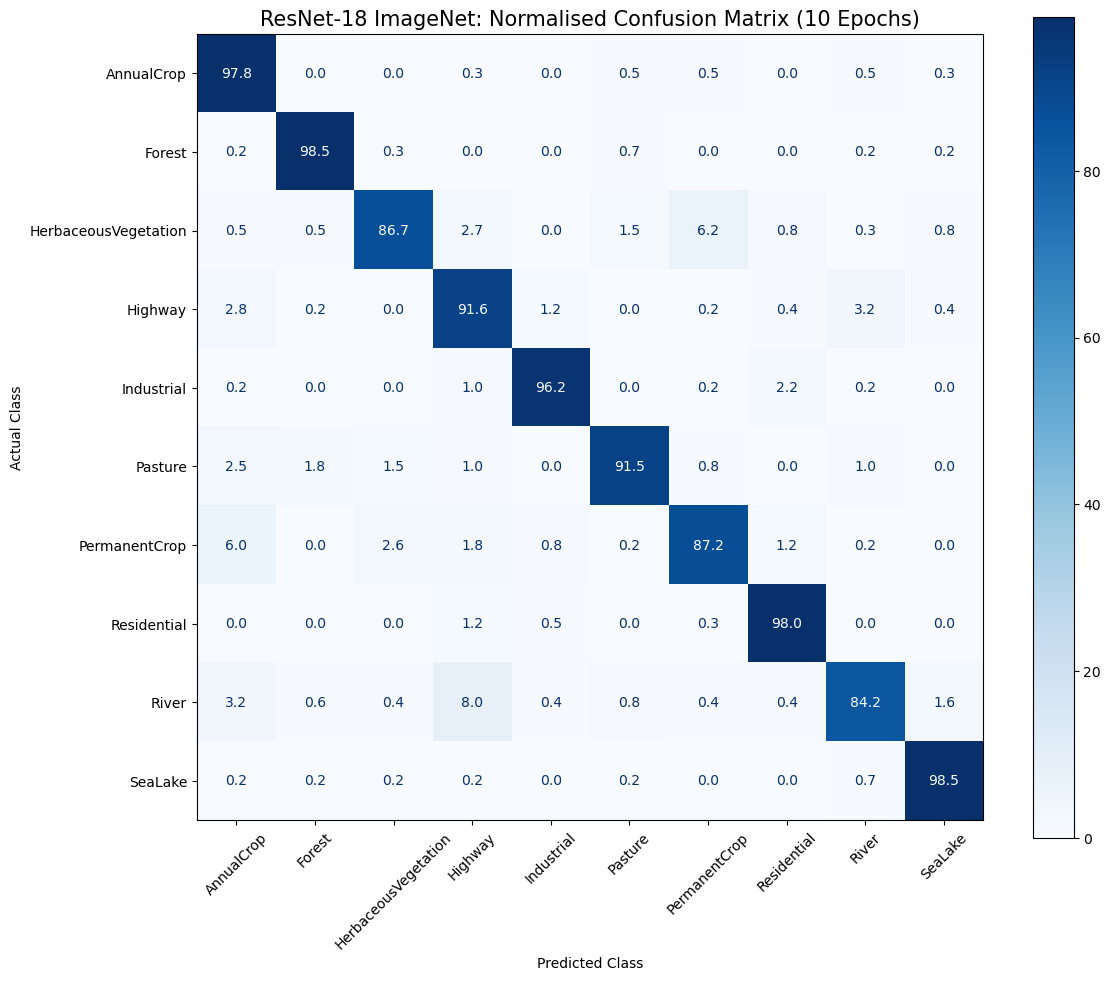

In [50]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Calculate normalised confusion matrix
cm_normalised = confusion_matrix(
    all_labels,
    all_predictions,
    normalize="true"
) * 100

# Create figure
fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalised,
    display_labels=test_dataset.classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format=".1f",
    colorbar=True
)

plt.title(
    "ResNet-18 ImageNet: Normalised Confusion Matrix (10 Epochs)",
    fontsize=15
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [51]:
# Continue training from epoch 10 to epoch 15
history_extra_5, extra_training_time = train_model(
    model,
    train_loader,
    criterion,
    optimizer,
    device,
    epochs=5
)

print("\nModel has now completed 15 epochs in total!")

Epoch 1/5 | Loss: 0.1537 | Training accuracy: 95.59% | Time: 4.55 minutes
------------------------------------------------------------
------------------------------------------------------------
Epoch 2/5 | Loss: 0.1466 | Training accuracy: 95.79% | Time: 3.11 minutes
------------------------------------------------------------
Epoch 3/5 | Loss: 0.1582 | Training accuracy: 95.59% | Time: 3.45 minutes
------------------------------------------------------------
Epoch 4/5 | Loss: 0.1494 | Training accuracy: 95.65% | Time: 3.46 minutes
------------------------------------------------------------
Epoch 5/5 | Loss: 0.1361 | Training accuracy: 96.10% | Time: 2.95 minutes
------------------------------------------------------------

Training completed!
Total training time: 17.52 minutes

Model has now completed 15 epochs in total!


Testing 15-epoch ResNet-18:   0%|          | 0/169 [00:00<?, ?it/s]


15-EPOCH RESNET-18 TEST RESULTS
Test images: 5400
Test accuracy: 93.69%
Test loss: 0.3216
Evaluation time: 59.69 seconds


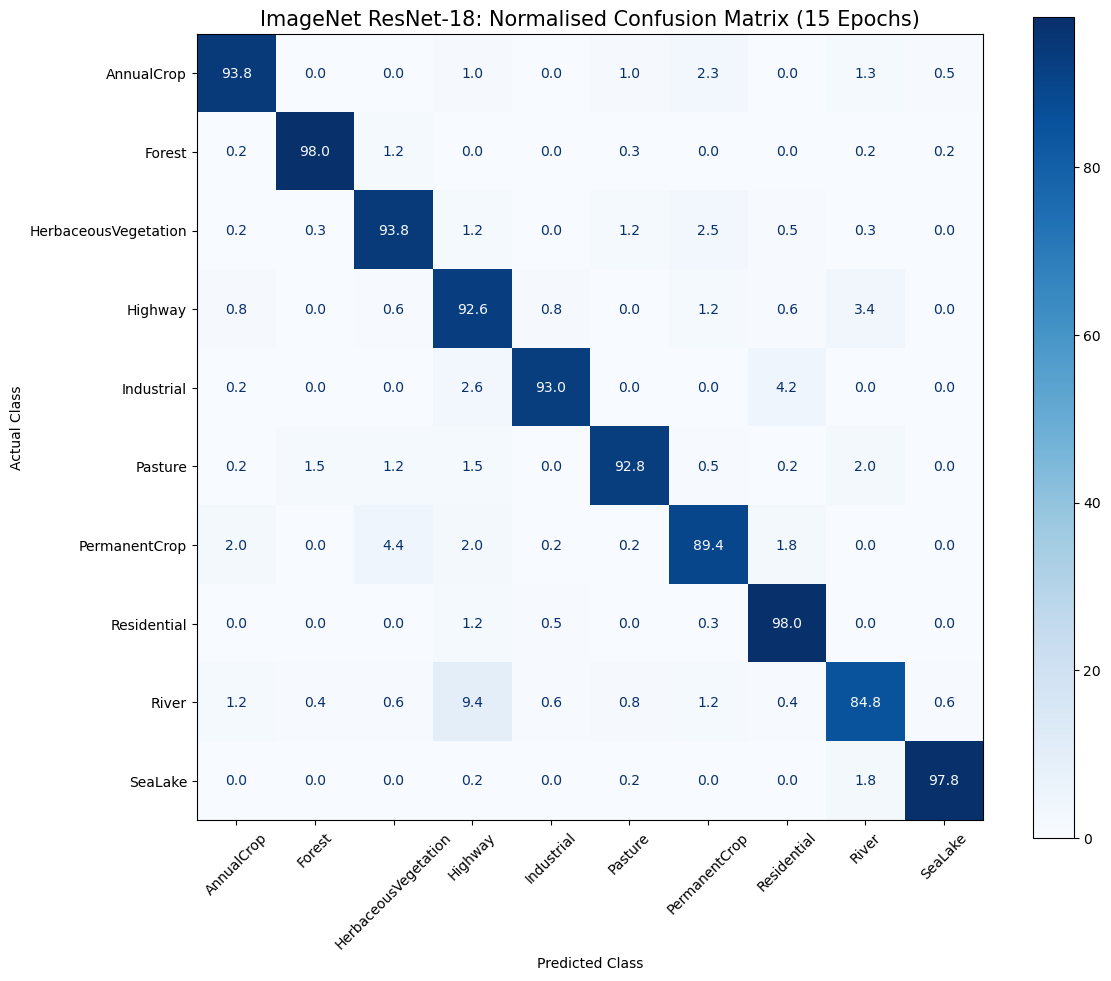


CLASSIFICATION REPORT
                      precision    recall  f1-score   support

          AnnualCrop       0.96      0.94      0.95       600
              Forest       0.98      0.98      0.98       600
HerbaceousVegetation       0.93      0.94      0.94       600
             Highway       0.83      0.93      0.87       500
          Industrial       0.98      0.93      0.95       500
             Pasture       0.95      0.93      0.94       400
       PermanentCrop       0.91      0.89      0.90       500
         Residential       0.94      0.98      0.96       600
               River       0.90      0.85      0.87       500
             SeaLake       0.99      0.98      0.98       600

            accuracy                           0.94      5400
           macro avg       0.94      0.93      0.93      5400
        weighted avg       0.94      0.94      0.94      5400



In [52]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)
from tqdm.auto import tqdm

# Use the trained 15-epoch model already in memory
# If necessary, uncomment the lines below to load the saved checkpoint:
#
# checkpoint = torch.load(
#     "resnet18_imagenet_15epochs_checkpoint.pth",
#     map_location=device,
#     weights_only=True
# )
# model.load_state_dict(checkpoint["model_state_dict"])

model = model.to(device)
model.eval()

all_predictions = []
all_labels = []

total_loss = 0.0
total_images = 0

start_time = time.perf_counter()

# Evaluate all 5,400 test images
with torch.inference_mode():

    for images, labels in tqdm(
        test_loader,
        desc="Testing 15-epoch ResNet-18"
    ):

        images = images.to(device)
        labels = labels.to(device)

        # Generate predictions
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        total_loss += loss.item() * labels.size(0)
        total_images += labels.size(0)

        # Predicted classes
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

# Synchronise GPU before recording time
if device.type == "mps":
    torch.mps.synchronize()
elif device.type == "cuda":
    torch.cuda.synchronize()

test_time = time.perf_counter() - start_time

# Calculate overall metrics
test_accuracy = accuracy_score(
    all_labels,
    all_predictions
) * 100

test_loss = total_loss / total_images

print("\n15-EPOCH RESNET-18 TEST RESULTS")
print("=" * 45)
print(f"Test images: {total_images}")
print(f"Test accuracy: {test_accuracy:.2f}%")
print(f"Test loss: {test_loss:.4f}")
print(f"Evaluation time: {test_time:.2f} seconds")

# Calculate normalised confusion matrix (%)
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=range(len(test_dataset.classes)),
    normalize="true"
) * 100

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format=".1f",
    colorbar=True
)

ax.set_title(
    "ImageNet ResNet-18: Normalised Confusion Matrix (15 Epochs)",
    fontsize=15
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

# Print per-class classification results
print("\nCLASSIFICATION REPORT")
print("=" * 45)

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=range(len(test_dataset.classes)),
        target_names=test_dataset.classes,
        zero_division=0
    )
)

In [53]:
import torch

torch.save({
    "epoch": 15,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict()
}, "resnet18_imagenet_15epochs_checkpoint.pth")

print("15-epoch checkpoint saved!")

15-epoch checkpoint saved!


### Training the 4th and last layer[¶](#Training-the-4th-and-last-layer)

In [58]:
import torch
import torch.nn as nn
import time

from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader

# Reproducibility
torch.manual_seed(42)

# Select device
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

# Fresh ImageNet-pretrained ResNet-18
model_ft = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

# Freeze all pretrained layers
for param in model_ft.parameters():
    param.requires_grad = False

# Replace the final classification layer
model_ft.fc = nn.Linear(
    model_ft.fc.in_features,
    10
)

# Unfreeze layer4
for param in model_ft.layer4.parameters():
    param.requires_grad = True

# Move model to GPU
model_ft = model_ft.to(device)

# Loss function
criterion_ft = nn.CrossEntropyLoss()

# Different learning rates for each layer
optimizer_ft = torch.optim.Adam([
    {
        "params": model_ft.layer4.parameters(),
        "lr": 0.0001
    },
    {
        "params": model_ft.fc.parameters(),
        "lr": 0.001
    }
])

# Full training dataset with batch size 16
train_loader_ft = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

print("Device:", device)
print("Training images:", len(train_dataset))
print("Batches:", len(train_loader_ft))

print("Trainable parameters:", sum(
    p.numel()
    for p in model_ft.parameters()
    if p.requires_grad
))

Device: mps
Training images: 21600
Batches: 675
Trainable parameters: 8398858


In [59]:
# Enable training for layer4 and fc
model_ft.train()

# Keep BatchNorm running statistics frozen
for module in model_ft.modules():
    if isinstance(module, nn.BatchNorm2d):
        module.eval()

running_loss = 0.0
correct = 0
total = 0

start_time = time.perf_counter()

for images, labels in train_loader_ft:

    images = images.to(device)
    labels = labels.to(device)

    optimizer_ft.zero_grad(set_to_none=True)

    # Forward pass
    outputs = model_ft(images)

    # Calculate loss
    loss = criterion_ft(outputs, labels)

    # Backpropagation
    loss.backward()

    # Update layer4 and fc
    optimizer_ft.step()

    # Training statistics
    running_loss += loss.item() * labels.size(0)

    predictions = outputs.argmax(dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

# Synchronise GPU for accurate timing
if device.type == "mps":
    torch.mps.synchronize()

training_time = time.perf_counter() - start_time

train_loss = running_loss / total
train_accuracy = 100 * correct / total

print("\nONE-EPOCH FINE-TUNING RESULTS")
print("=" * 45)

print(f"Training images: {total}")
print(f"Training loss: {train_loss:.4f}")
print(f"Training accuracy: {train_accuracy:.2f}%")

print(f"\nTime per epoch: {training_time/60:.2f} minutes")

# Estimate 15-epoch training time
estimated_15 = training_time * 15

print(f"Estimated 15-epoch time: {estimated_15/60:.2f} minutes")
print(f"Estimated 15-epoch time: {estimated_15/3600:.2f} hours")


ONE-EPOCH FINE-TUNING RESULTS
Training images: 21600
Training loss: 0.2256
Training accuracy: 92.51%

Time per epoch: 5.49 minutes
Estimated 15-epoch time: 82.33 minutes
Estimated 15-epoch time: 1.37 hours


In [60]:
import torch
import time
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
from tqdm.auto import tqdm


def test_model(model, test_loader, criterion, device):

    model.eval()

    all_predictions = []
    all_labels = []

    total_loss = 0.0
    correct = 0
    total = 0

    start_time = time.perf_counter()

    with torch.inference_mode():

        for images, labels in tqdm(
            test_loader,
            desc="Testing ResNet-18"
        ):

            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Predictions
            predictions = outputs.argmax(dim=1)

            # Accumulate results
            total_loss += loss.item() * labels.size(0)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            all_predictions.extend(
                predictions.cpu().tolist()
            )

            all_labels.extend(
                labels.cpu().tolist()
            )

    # Synchronise GPU for accurate timing
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

    test_time = time.perf_counter() - start_time

    test_loss = total_loss / total
    test_accuracy = 100 * correct / total

    print("\nRESNET-18 TEST RESULTS")
    print("=" * 45)
    print(f"Test images: {total}")
    print(f"Test loss: {test_loss:.4f}")
    print(f"Test accuracy: {test_accuracy:.2f}%")
    print(f"Evaluation time: {test_time/60:.2f} minutes")

    # Normalised confusion matrix (percentages)
    cm = confusion_matrix(
        all_labels,
        all_predictions,
        labels=range(len(test_loader.dataset.classes)),
        normalize="true"
    ) * 100

    fig, ax = plt.subplots(figsize=(12, 10))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=test_loader.dataset.classes
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        values_format=".1f"
    )

    ax.set_title(
        "ResNet-18 (Layer4 + FC Fine-Tuning) — Confusion Matrix"
    )

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

    plt.tight_layout()
    plt.show()

    # Classification report
    print("\nCLASSIFICATION REPORT")
    print("=" * 45)

    print(
        classification_report(
            all_labels,
            all_predictions,
            target_names=test_loader.dataset.classes,
            zero_division=0
        )
    )

    return {
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "test_time": test_time,
        "predictions": all_predictions,
        "labels": all_labels
    }

Testing ResNet-18:   0%|          | 0/169 [00:00<?, ?it/s]


RESNET-18 TEST RESULTS
Test images: 5400
Test loss: 0.1216
Test accuracy: 95.80%
Evaluation time: 1.08 minutes


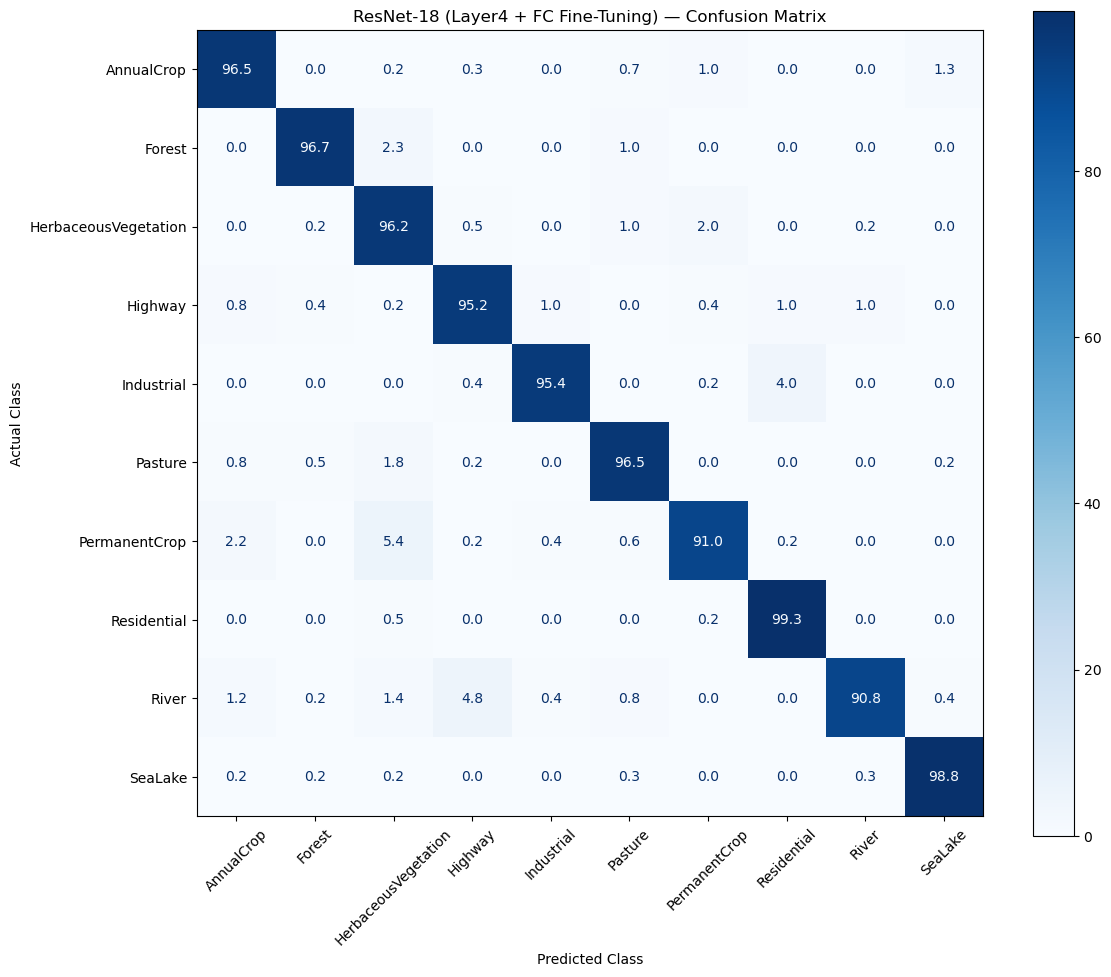


CLASSIFICATION REPORT
                      precision    recall  f1-score   support

          AnnualCrop       0.96      0.96      0.96       600
              Forest       0.99      0.97      0.98       600
HerbaceousVegetation       0.90      0.96      0.93       600
             Highway       0.94      0.95      0.94       500
          Industrial       0.98      0.95      0.97       500
             Pasture       0.94      0.96      0.95       400
       PermanentCrop       0.95      0.91      0.93       500
         Residential       0.96      0.99      0.98       600
               River       0.98      0.91      0.94       500
             SeaLake       0.98      0.99      0.99       600

            accuracy                           0.96      5400
           macro avg       0.96      0.96      0.96      5400
        weighted avg       0.96      0.96      0.96      5400



In [61]:
results_ft = test_model(
    model_ft,
    test_loader,
    criterion_ft,
    device
)

In [62]:
import torch
import torch.nn as nn
import time

def continue_finetuning(
    model,
    train_loader,
    criterion,
    optimizer,
    device,
    epochs=4
):
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "epoch_time": []
    }

    total_start = time.perf_counter()

    for epoch in range(epochs):

        # Train layer4 and fc
        model.train()

        # Keep BatchNorm running statistics fixed
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()

        running_loss = 0.0
        correct = 0
        total = 0

        epoch_start = time.perf_counter()

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backpropagation
            loss.backward()
            optimizer.step()

            # Calculate training metrics
            running_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        # Synchronise MPS GPU before timing
        if device.type == "mps":
            torch.mps.synchronize()
        elif device.type == "cuda":
            torch.cuda.synchronize()

        epoch_time = time.perf_counter() - epoch_start

        train_loss = running_loss / total
        train_accuracy = 100 * correct / total

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["epoch_time"].append(epoch_time)

        print(
            f"Epoch {epoch + 2}/5 | "
            f"Loss: {train_loss:.4f} | "
            f"Training accuracy: {train_accuracy:.2f}% | "
            f"Time: {epoch_time / 60:.2f} minutes",
            flush=True
        )

    total_time = time.perf_counter() - total_start

    print("\nTraining completed!")
    print(f"Total additional training time: {total_time / 60:.2f} minutes")

    return history, total_time

In [63]:
history_ft_2to5, training_time_ft_2to5 = continue_finetuning(
    model_ft,
    train_loader_ft,
    criterion_ft,
    optimizer_ft,
    device,
    epochs=4
)

Epoch 2/5 | Loss: 0.1073 | Training accuracy: 96.36% | Time: 4.86 minutes
Epoch 3/5 | Loss: 0.0784 | Training accuracy: 97.46% | Time: 5.50 minutes
Epoch 4/5 | Loss: 0.0589 | Training accuracy: 97.98% | Time: 5.08 minutes
Epoch 5/5 | Loss: 0.0479 | Training accuracy: 98.29% | Time: 5.74 minutes

Training completed!
Total additional training time: 21.18 minutes


In [64]:
torch.save({
    "epoch": 5,
    "model_state_dict": model_ft.state_dict(),
    "optimizer_state_dict": optimizer_ft.state_dict(),
    "history_2to5": history_ft_2to5,
    "training_time_2to5": training_time_ft_2to5,
    "layer4_lr": 0.0001,
    "fc_lr": 0.001,
    "batch_size": 16
}, "resnet18_layer4_fc_5epochs.pth")

print("5-epoch fine-tuned model saved!")

5-epoch fine-tuned model saved!


Testing ResNet-18:   0%|          | 0/169 [00:00<?, ?it/s]


RESNET-18 TEST RESULTS
Test images: 5400
Test loss: 0.0918
Test accuracy: 97.37%
Evaluation time: 0.93 minutes


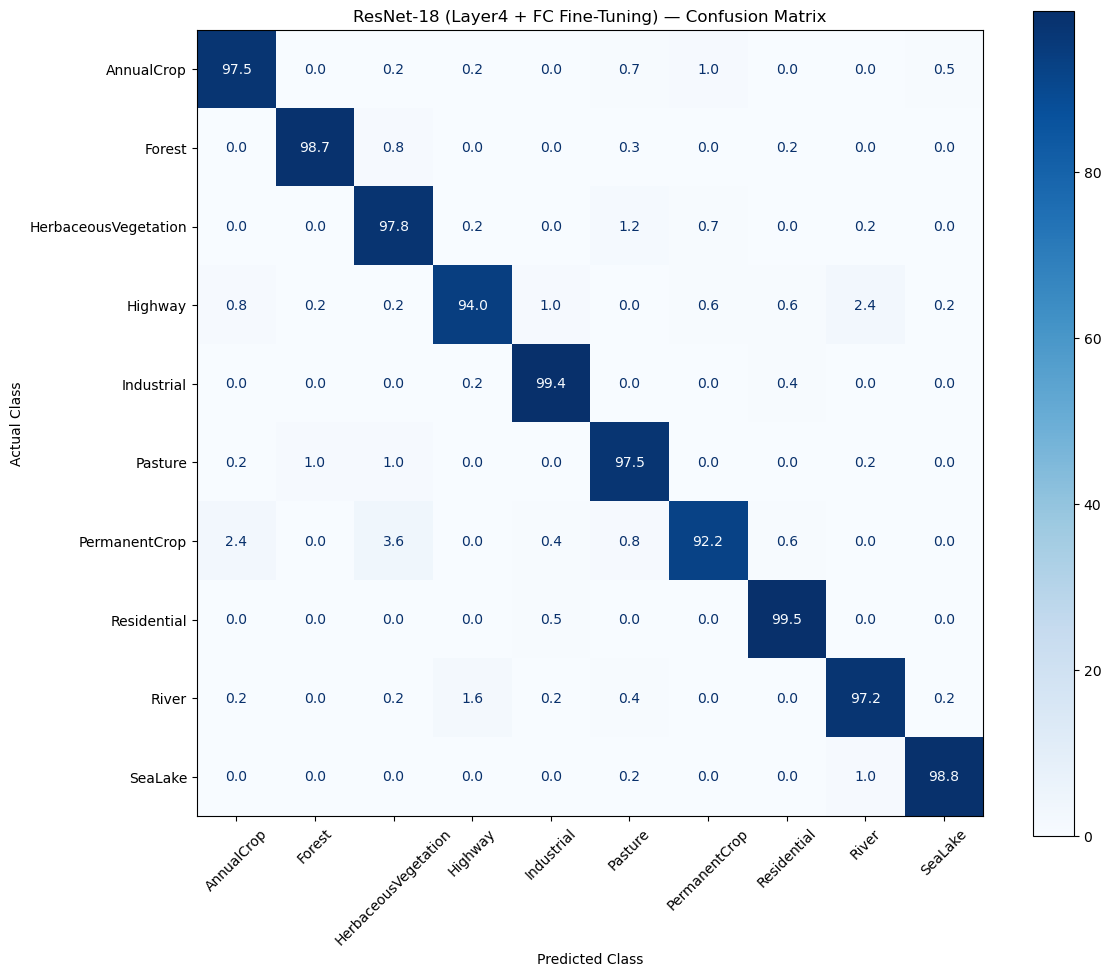


CLASSIFICATION REPORT
                      precision    recall  f1-score   support

          AnnualCrop       0.97      0.97      0.97       600
              Forest       0.99      0.99      0.99       600
HerbaceousVegetation       0.95      0.98      0.96       600
             Highway       0.98      0.94      0.96       500
          Industrial       0.98      0.99      0.99       500
             Pasture       0.95      0.97      0.96       400
       PermanentCrop       0.97      0.92      0.95       500
         Residential       0.99      0.99      0.99       600
               River       0.96      0.97      0.97       500
             SeaLake       0.99      0.99      0.99       600

            accuracy                           0.97      5400
           macro avg       0.97      0.97      0.97      5400
        weighted avg       0.97      0.97      0.97      5400



In [65]:
results_ft_5epochs = test_model(
    model_ft,
    test_loader,
    criterion_ft,
    device
)

In [66]:
import torch
import torch.nn as nn
import time

def continue_finetuning(
    model,
    train_loader,
    criterion,
    optimizer,
    device,
    epochs=5,
    starting_epoch=5
):
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "epoch_time": []
    }

    total_start = time.perf_counter()

    for epoch in range(epochs):

        # Enable training for layer4 and fc
        model.train()

        # Keep BatchNorm running statistics fixed
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()

        running_loss = 0.0
        correct = 0
        total = 0

        epoch_start = time.perf_counter()

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backpropagation
            loss.backward()
            optimizer.step()

            # Training statistics
            running_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        # Synchronise GPU before measuring elapsed time
        if device.type == "mps":
            torch.mps.synchronize()
        elif device.type == "cuda":
            torch.cuda.synchronize()

        epoch_time = time.perf_counter() - epoch_start

        train_loss = running_loss / total
        train_accuracy = 100 * correct / total

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["epoch_time"].append(epoch_time)

        print(
            f"Epoch {starting_epoch + epoch + 1}/"
            f"{starting_epoch + epochs} | "
            f"Loss: {train_loss:.4f} | "
            f"Training accuracy: {train_accuracy:.2f}% | "
            f"Time: {epoch_time / 60:.2f} minutes",
            flush=True
        )

    total_time = time.perf_counter() - total_start

    print("\nTraining completed!")
    print(f"Additional training time: {total_time / 60:.2f} minutes")

    return history, total_time

In [67]:
history_ft_6to10, training_time_ft_6to10 = continue_finetuning(
    model_ft,
    train_loader_ft,
    criterion_ft,
    optimizer_ft,
    device,
    epochs=5,
    starting_epoch=5
)

Epoch 6/10 | Loss: 0.0409 | Training accuracy: 98.62% | Time: 4.89 minutes
Epoch 7/10 | Loss: 0.0284 | Training accuracy: 99.09% | Time: 5.30 minutes
Epoch 8/10 | Loss: 0.0275 | Training accuracy: 99.12% | Time: 5.22 minutes
Epoch 9/10 | Loss: 0.0260 | Training accuracy: 99.12% | Time: 4.80 minutes
Epoch 10/10 | Loss: 0.0236 | Training accuracy: 99.23% | Time: 5.25 minutes

Training completed!
Additional training time: 25.45 minutes


In [68]:
torch.save({
    "epoch": 10,
    "model_state_dict": model_ft.state_dict(),
    "optimizer_state_dict": optimizer_ft.state_dict(),
    "history_6to10": history_ft_6to10,
    "training_time_6to10": training_time_ft_6to10,
    "layer4_lr": 0.0001,
    "fc_lr": 0.001,
    "batch_size": 16
}, "resnet18_layer4_fc_10epochs.pth")

print("10-epoch fine-tuned model saved!")

10-epoch fine-tuned model saved!


Testing ResNet-18:   0%|          | 0/169 [00:00<?, ?it/s]


RESNET-18 TEST RESULTS
Test images: 5400
Test loss: 0.1306
Test accuracy: 96.69%
Evaluation time: 1.30 minutes


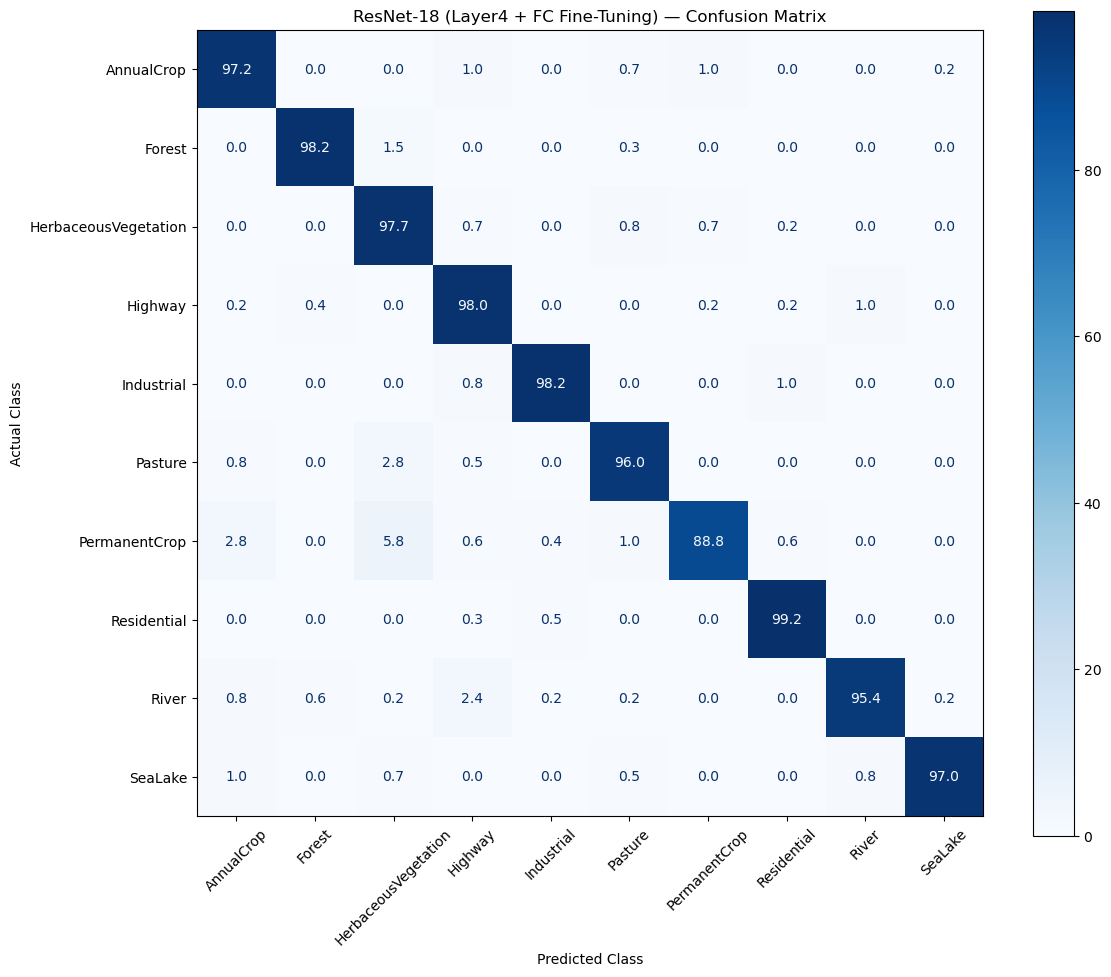


CLASSIFICATION REPORT
                      precision    recall  f1-score   support

          AnnualCrop       0.95      0.97      0.96       600
              Forest       0.99      0.98      0.99       600
HerbaceousVegetation       0.92      0.98      0.95       600
             Highway       0.94      0.98      0.96       500
          Industrial       0.99      0.98      0.98       500
             Pasture       0.95      0.96      0.96       400
       PermanentCrop       0.98      0.89      0.93       500
         Residential       0.98      0.99      0.99       600
               River       0.98      0.95      0.97       500
             SeaLake       1.00      0.97      0.98       600

            accuracy                           0.97      5400
           macro avg       0.97      0.97      0.97      5400
        weighted avg       0.97      0.97      0.97      5400



In [69]:
results_ft_10epochs = test_model(
    model_ft,
    test_loader,
    criterion_ft,
    device
)